# 1. MLP and Input-Output Convex Neural Networks

# 1.2 MLP implementation from scratch

In [1]:
%pip install numpy datasets matplotlib wandb

  Using cached pyyaml-6.0.3-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (2.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 55.2 kB/s  0:04:51 eta 0:00:040:00:09
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 40.1 kB/s  0:00:15 37.3 kB/s eta 0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 47.9 kB/s  0:00:167.7 kB/s eta 0:00:02:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 53.1 kB/s  0:01:20 eta 0:00:010:06:11
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 60.7 kB/s  0:02:47a 0:00:030:00:07:27
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 57.6 kB/s  0:05:56 eta 0:00:030:00:12
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 40.9 kB/s  0:00:48 40.2 kB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 47.8 kB/s  0:00:396.7 kB/s eta 0:00:02:08
Using cached cycler-0.12.1-py3-none-any

In [1]:
import numpy as np

ROLL_NUMBER = 2026701036
SEED = ROLL_NUMBER % 100000
RUN = 0
print("Seed for question 1:", SEED)

Seed for question 1: 1036


In [2]:
from datasets import load_dataset

ds = load_dataset("uoft-cs/cifar10")

X = np.empty((60_000,32,32,3),dtype=np.uint8)
y = np.empty(60_000, dtype=np.int64)

for i, img in enumerate(ds["train"]["img"]):
    X[i] = np.asarray(img, dtype=np.uint8)
for i, img in enumerate(ds["test"]["img"]):
    X[50_000 + i] = np.asarray(img, dtype=np.uint8)

y[:50_000] = np.asarray(ds["train"]["label"], dtype=np.int64)
y[50_000:] = np.asarray(ds["test"]["label"], dtype=np.int64)

print("X:", X.shape,X.dtype)
print("y:", y.shape,y.dtype)
print("per-class counts:", np.bincount(y, minlength=10))

/home/surya/work/research/SMAI-A4/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


X: (60000, 32, 32, 3) uint8
y: (60000,) int64
per-class counts: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


In [3]:
X = X.reshape(60_000,32*32*3)

def stratified_split(y, rng, n_train, n_val, n_test):
    train_idx, val_idx, test_idx = [], [], []
    for c in np.unique(y):
        idx = np.flatnonzero(y == c)
        idx = rng.permutation(idx)
        assert len(idx) >= n_train+n_val+n_test
        train_idx.append(idx[:n_train])
        val_idx.append(idx[n_train:n_train+n_val])
        test_idx.append(idx[n_train+n_val:n_train+n_val+n_test])
    return (np.concatenate(train_idx),np.concatenate(val_idx),np.concatenate(test_idx))

rng_split = np.random.default_rng(SEED+100*RUN+0)
train_idx,val_idx,test_idx = stratified_split(y,rng_split,3600,1200,1200)

print("train counts:", np.bincount(y[train_idx],minlength=10))
print("val counts:", np.bincount(y[val_idx],minlength=10))
print("test counts:", np.bincount(y[test_idx],minlength=10))

train counts: [3600 3600 3600 3600 3600 3600 3600 3600 3600 3600]
val counts: [1200 1200 1200 1200 1200 1200 1200 1200 1200 1200]
test counts: [1200 1200 1200 1200 1200 1200 1200 1200 1200 1200]


In [4]:
X_train = X[train_idx].astype(np.float64)
X_val = X[val_idx].astype(np.float64)
X_test = X[test_idx].astype(np.float64)

X_train /= 255.0
X_val /= 255.0
X_test /= 255.0

y_train = y[train_idx].copy()
y_val = y[val_idx].copy()
y_test = y[test_idx].copy()

train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)

train_std[train_std ==0.0] = 1.0

X_train -= train_mean
X_train /= train_std
X_val -= train_mean
X_val /= train_std
X_test -= train_mean
X_test /= train_std

print("train mean first 3:", X_train.mean(axis=0)[:3])
print("train std first 3:", X_train.std(axis=0)[:3])
print("test mean first 3:", X_test.mean(axis=0)[:3])
print("test std first 3:", X_test.std(axis=0)[:3])

print("X_train:", X_train.shape, X_train.dtype)
print("X_val:", X_val.shape, X_val.dtype)
print("X_test:", X_test.shape, X_test.dtype)

train mean first 3: [1.40387597e-14 4.61716899e-14 4.00795570e-14]
train std first 3: [1. 1. 1.]
test mean first 3: [ 0.00231415  0.00064378 -0.00472698]
test std first 3: [1.00449637 1.00379161 1.00436622]
X_train: (36000, 3072) float64
X_val: (12000, 3072) float64
X_test: (12000, 3072) float64


the test mean and std of the above results are not exactly 0 and 1 because the standardisation statistics were computed on the training split only, the test split is different sample and therefore has slightly differnet statis

In [5]:
print(y_train.dtype, y_train.shape, np.unique(y_train))
print(y_val.dtype, y_val.shape, np.unique(y_val))
print(y_test.dtype, y_test.shape, np.unique(y_test))

int64 (36000,) [0 1 2 3 4 5 6 7 8 9]
int64 (12000,) [0 1 2 3 4 5 6 7 8 9]
int64 (12000,) [0 1 2 3 4 5 6 7 8 9]


In [6]:
class Linear:
    def __init__(self,n_in,n_out,activation,rng):
        self.n_in = n_in
        self.n_out = n_out
        self.activation = activation

        # for relu variance 2/n_in and for all other 1/n_in
        variance = 2.0/n_in if isinstance(activation,ReLU) else 1.0/n_in

        self.W = rng.normal(0.0,np.sqrt(variance), size=(n_in,n_out))
        self.b = np.zeros(n_out, dtype=np.float64)

        #cumulative gradients summer over the train call
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

        # forward pass cache
        self.x = None #input to the layer
        self.z = None #pre-activation
        self.h = None #post-activation output

    def forward(self, x):
        self.x = x
        self.z = x @ self.W + self.b
        self.h = self.activation.forward(self.z)
        return self.h

    def backward(self, dout):
        # gradient of output dout = dL/dh for thhis layers output
        dz = dout * self.activation.backward(self.z)
        self.dW += self.x.T@dz
        self.db += dz.sum(axis=0)
        return dz @ self.W.T

    def zero_grad(self):
        self.dW.fill(0.0)
        self.db.fill(0.0)

In [7]:
class ReLU:
    def forward(self, z):
        return np.maximum(0.0,z)
    def backward(self, z):
        return (z > 0.0).astype(np.float64)

class Tanh:
    def forward(self, z):
        return np.tanh(z)
    def backward(self, z):
        t = np.tanh(z)
        return 1.0 - t*t

class Sigmoid:
    def forward(self, z):
        z = np.asarray(z, dtype=np.float64)
        e = np.exp(-np.abs(z))
        return np.where(z >= 0.0,1.0/(1.0+e),e/(1.0+e))
    def backward(self, z):
        s = self.forward(z)
        return s*(1.0-s)

class Identity:
    def forward(self, z):
        return z
    def backward(self, z):
        return np.ones_like(z, dtype=np.float64)

In [8]:
# quick test for the above classes implemented

rng_test = np.random.default_rng(SEED + 100 * RUN + 1)

layer = Linear(3,4,ReLU(),rng_test)
x = np.random.default_rng(123).normal(size=(5,3))
h = layer.forward(x)

print("W:", layer.W.shape, "b:", layer.b.shape)
print("z:", layer.z.shape, "h:", h.shape)
print("bias is zero:", np.all(layer.b == 0.0))
print("grads start at zero:", np.all(layer.dW == 0.0), np.all(layer.db == 0.0))

dx = layer.backward(np.ones_like(h))
print("dx:", dx.shape)
print("dW:", layer.dW.shape, "db:", layer.db.shape)

layer.zero_grad()
print("after zero_grad:", np.all(layer.dW == 0.0), np.all(layer.db == 0.0))

rng_v = np.random.default_rng(7)
relu_layer = Linear(1000, 10, ReLU(), rng_v)
tanh_layer = Linear(1000, 10, Tanh(), rng_v)

print("ReLU W variance:", relu_layer.W.var(), "expected:", 2/1000)
print("Tanh W variance:", tanh_layer.W.var(), "expected:", 1/1000)

W: (3, 4) b: (4,)
z: (5, 4) h: (5, 4)
bias is zero: True
grads start at zero: True True
dx: (5, 3)
dW: (3, 4) db: (4,)
after zero_grad: True True
ReLU W variance: 0.0019771671435858808 expected: 0.002
Tanh W variance: 0.0009811740048855106 expected: 0.001


In [8]:
# model classes and losses

class Model:
    def __init__(self, layers, loss_type):
        self.layers = layers
        self.loss_type = loss_type.lower()

        if self.loss_type not in ("mse","bce","cce"):
            raise ValueError("loss_type must be either mse or bce or cce")
        self._accum_count = 0

    def forward(self, x):
        h = x
        for layer in self.layers:
            h = layer.forward(h)
        return h
    
    def backward(self, dout):
        g = dout
        for layer in reversed(self.layers):
            g = layer.backward(g)
        return g
    
    def zero_grad(self):
        for layer in self.layers:
            layer.zero_grad()
        self._accum_count = 0

    def train(self, x, y):
        out = self.forward(x)
        loss, dout = self._loss(out,y)
        self.backward(dout)
        self._accum_count += 1
        return loss

    def update(self, lr):
        m = max(1, self._accum_count)
        for layer in self.layers:
            layer.W -= lr * layer.dW/m
            layer.b -= lr * layer.db/m
        self.zero_grad()

    def predict(self, x):
        out = self.forward(x)
        if self.loss_type == "cce":
            return self._softmax(out)
        return out

    def _softmax(self, logits):
        m = logits.max(axis=1, keepdims=True)
        e = np.exp(logits - m)
        return e/e.sum(axis=1, keepdims=True)

    def _loss(self, out, y):
        if self.loss_type == "mse":
            target = np.asarray(y, dtype=np.float64)
            if target.shape != out.shape:
                target = target.reshape(out.shape)
            diff = out - target
            loss = np.mean(diff*diff)
            dout = 2.0 * diff/diff.size
            return loss, dout

        if self.loss_type == "bce":
            p = np.clip(out, 1e-12, 1.0 - 1e-12)
            target = np.asarray(y, dtype=np.float64).reshape(p.shape)
            loss = -np.mean(target*np.log(p) + (1.0-target)*np.log(1.0-p))
            dout = (-target/p + (1.0 - target) / (1.0 -p))/p.size
            return loss, dout

        logits = np.asarray(out, dtype=np.float64)
        labels = np.asarray(y, dtype=np.int64).reshape(-1)
        B = logits.shape[0]

        m = logits.max(axis=1, keepdims=True)
        exp = np.exp(logits - m)
        sumexp = exp.sum(axis=1, keepdims=True)
        p = exp/sumexp

        logsumexp = (m + np.log(sumexp))[:,0]
        loss = np.mean(logsumexp - logits[np.arange(B), labels])

        dout = p
        dout[np.arange(B), labels] -= 1.0
        dout /= B

        return loss, dout

    def save_to(self, path):
        path = str(path)
        if not path.lower().endswith(".npz"):
            path += ".npz"

        arrays = {}
        for i, layer in enumerate(self.layers):
            arrays[f"W{i}"] = layer.W
            arrays[f"b{i}"] = layer.b

        np.savez(path, **arrays)

    def load_from(self, path):
        path = str(path)
        if not path.lower().endswith(".npz"):
            path += ".npz"
        with np.load(path) as data:
            if len(data.files) != 2*len(self.layers):
                raise ValueError("wrong no of parameter array")
            for i, layer in enumerate(self.layers):
                try:
                    W = data[f"W{i}"]
                    b = data[f"b{i}"]
                except KeyError as exc:
                    raise ValueError(f"mmissing parameters for layer {i}") from exc
                if W.shape != layer.W.shape or b.shape != layer.b.shape:
                    raise ValueError(f"mismath in layer {i}: saved {W.shape}/{b.shape}, current {layer.W.shape}/{layer.b.shape}")

            for i, layer in enumerate(self.layers):
                layer.W[...] = data[f"W{i}"]
                layer.b[...] = data[f"b{i}"]
        self.zero_grad()

In [13]:
#test cell
rng_cce = np.random.default_rng(SEED + 100 * RUN + 1)
cce_model = Model(
    [Linear(2, 5, Tanh(), rng_cce), Linear(5, 3, Identity(), rng_cce)],
    "cce",
)
xb = np.random.default_rng(1).normal(size=(4, 2))
yb = np.array([0, 1, 2, 1])
loss = cce_model.train(xb, yb)
probs = cce_model.predict(xb)

print("CCE loss:", loss)
print("probs shape:", probs.shape)
print("row sums:", probs.sum(axis=1))
print("grads nonzero:", [np.any(l.dW != 0.0) for l in cce_model.layers])

W_before = cce_model.layers[0].W.copy()
cce_model.update(0.1)
print("weights changed:", not np.allclose(W_before, cce_model.layers[0].W))
print("grads zero after update:", [np.all(l.dW == 0.0) for l in cce_model.layers])

rng_bce = np.random.default_rng(SEED + 100 * RUN + 1)
bce_model = Model(
    [Linear(2, 4, Tanh(), rng_bce), Linear(4, 1, Sigmoid(), rng_bce)],
    "bce",
)
xb = np.random.default_rng(2).normal(size=(6, 2))
yb = np.array([0, 1, 1, 0, 1, 0])
loss = bce_model.train(xb, yb)
p = bce_model.predict(xb)
print("BCE loss:", loss)
print("p shape:", p.shape, "p range:", p.min(), p.max())

rng_mse = np.random.default_rng(SEED + 100 * RUN + 1)
mse_model = Model(
    [Linear(2, 3, Tanh(), rng_mse), Linear(3, 2, Identity(), rng_mse)],
    "mse",
)
xb = np.random.default_rng(3).normal(size=(5, 2))
yb = np.random.default_rng(4).normal(size=(5, 2))
loss = mse_model.train(xb, yb)
print("MSE loss:", loss, "pred shape:", mse_model.predict(xb).shape)

cce_model.save_to("/tmp/cce_model.npz")
rng_copy = np.random.default_rng(123)
cce_copy = Model(
    [Linear(2, 5, Tanh(), rng_copy), Linear(5, 3, Identity(), rng_copy)],
    "cce",
)
cce_copy.load_from("/tmp/cce_model.npz")
print("load matches:", all(
    np.allclose(a.W, b.W) and np.allclose(a.b, b.b)
    for a, b in zip(cce_model.layers, cce_copy.layers)
))

try:
    rng_bad = np.random.default_rng(456)
    bad_model = Model(
        [Linear(2, 4, Tanh(), rng_bad), Linear(4, 3, Identity(), rng_bad)],
        "cce",
    )
    bad_model.load_from("/tmp/cce_model.npz")
except ValueError as exc:
    print("expected architecture error:", exc)

logits = np.array([
    [1000.0, 1001.0, 1002.0],
    [-1000.0, -1001.0, -1002.0],
])
labels = np.array([2, 0])
loss, grad = cce_model._loss(logits, labels)

print("large-logit CCE loss:", loss)
print("finite:", np.isfinite(loss))
print("grad row sums:", grad.sum(axis=1))

CCE loss: 1.3393735785610952
probs shape: (4, 3)
row sums: [1. 1. 1. 1.]
grads nonzero: [np.True_, np.True_]
weights changed: True
grads zero after update: [np.True_, np.True_]
BCE loss: 0.770619118340535
p shape: (6, 1) p range: 0.3173189895670321 0.5992580508308385
MSE loss: 2.5521364319456263 pred shape: (5, 2)
load matches: True
expected architecture error: mismath in layer 0: saved (2, 5)/(5,), current (2, 4)/(4,)
large-logit CCE loss: 0.40760596444442854
finite: True
grad row sums: [-5.55111512e-17 -5.55111512e-17]


In [9]:
def evaluate(model, X, y, batch_size=1024):
    n = len(X)
    total_loss = 0.0
    total_count = 0
    total_correct = 0
    for start in range(0, n, batch_size):
        xb = X[start:start + batch_size]
        yb = y[start:start + batch_size]
        out = model.forward(xb)
        loss, _ = model._loss(out, yb)
        total_loss += loss * yb.size
        total_count += yb.size
        if model.loss_type == "cce":
            pred = np.argmax(out, axis=1)
            total_correct += np.sum(pred == yb)
        elif model.loss_type == "bce":
            pred = (out.reshape(-1) > 0.5).astype(np.int64)
            total_correct += np.sum(pred == yb.reshape(-1))
    mean_loss = total_loss / total_count
    if model.loss_type in ("cce", "bce"):
        mean_acc = total_correct / n
    else:
        mean_acc = np.nan
    return mean_loss, mean_acc

In [10]:
def early_stop(val_losses, epoch, patience=5, relative_loss_threshold=0.01):
    """
    val_losses[0] = L0, the validation loss before training.
    val_losses[t] = validation loss at the end of epoch t.
    Stop when L_t >= (1 - threshold) * L_{t-patience}.
    """
    if epoch < patience:
        return False
    return (
        val_losses[epoch]
        >= (1.0 - relative_loss_threshold) * val_losses[epoch - patience]
    )

In [11]:
def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    batch_size=64,
    grad_accumulation_steps=1,
    lr=0.01,
    epochs=30,
    rng_batch=None,
    patience=5,
    relative_loss_threshold=0.01,
    wandb_run=None,
    log_every=50,
):
    if batch_size < 1 or grad_accumulation_steps < 1:
        raise ValueError("batch_size and grad_accumulation_steps must be >= 1")
    if rng_batch is None:
        rng_batch = np.random.default_rng(SEED + 100 * RUN + 2)
    if wandb_run is not None:
        wandb_run.config.update({
            "batch_size": batch_size,
            "grad_accumulation_steps": grad_accumulation_steps,
            "lr": lr,
            "epochs": epochs,
            "patience": patience,
            "relative_loss_threshold": relative_loss_threshold,
            "loss_type": model.loss_type,
            "n_layers": len(model.layers),
            "widths": [layer.n_in for layer in model.layers] + [model.layers[-1].n_out],
            "activations": [type(layer.activation).__name__ for layer in model.layers],
        })
    model.zero_grad()
    n = len(X_train)
    history = {
        "iter_loss": [],
        "samples_seen": [],
        "epoch": [],
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
    }
    val_loss0, _ = evaluate(model, X_val, y_val)
    val_losses = [val_loss0]
    history["val_loss0"] = val_loss0

    global_iter = 0
    stopped_epoch = epochs
    for epoch in range(1, epochs + 1):
        perm = rng_batch.permutation(n)
        n_batches = (n + batch_size - 1) // batch_size
        for j in range(n_batches):
            start = j * batch_size
            idx = perm[start:start + batch_size]
            loss = model.train(X_train[idx], y_train[idx])
            global_iter += 1
            samples_seen = (epoch - 1) * n + start + len(idx)
            history["iter_loss"].append(loss)
            history["samples_seen"].append(samples_seen)
            if wandb_run is not None and global_iter % log_every == 0:
                wandb_run.log({
                    "iter/train_loss": loss,
                    "iter/samples_seen": samples_seen,
                })
            if (j + 1) % grad_accumulation_steps == 0:
                model.update(lr)
        if n_batches % grad_accumulation_steps != 0:
            model.update(lr)
        train_loss, train_acc = evaluate(model, X_train, y_train)
        val_loss, val_acc = evaluate(model, X_val, y_val)
        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        val_losses.append(val_loss)
        if wandb_run is not None:
            wandb_run.log({
                "epoch": epoch,
                "epoch/train_loss": train_loss,
                "epoch/train_acc": train_acc,
                "epoch/val_loss": val_loss,
                "epoch/val_acc": val_acc,
            })
        if early_stop(val_losses, epoch, patience, relative_loss_threshold):
            print(f"Early stopping at epoch {epoch}")
            stopped_epoch = epoch
            break
    history["stopped_epoch"] = stopped_epoch
    history["val_losses"] = val_losses
    return history

In [20]:
#test for early stopping

print("before patience:", early_stop([1.0, 0.9, 0.8, 0.7], 4, 5, 0.01))
print("stopped (<1% drop):", early_stop([0.600, 0.59, 0.58, 0.57, 0.56, 0.595], 5, 5, 0.01))

before patience: False
stopped (<1% drop): True


In [21]:
rng_syn = np.random.default_rng(0)
centers = np.array([[0.0, 0.0], [4.0, 0.0], [0.0, 4.0]])
X_syn = np.vstack([rng_syn.normal(c, 0.8, size=(400, 2)) for c in centers])
y_syn = np.repeat(np.arange(3), 400)
perm = rng_syn.permutation(len(X_syn))
X_syn, y_syn = X_syn[perm], y_syn[perm]
X_tr, y_tr = X_syn[:900], y_syn[:900]
X_va, y_va = X_syn[900:1050], y_syn[900:1050]
X_te, y_te = X_syn[1050:], y_syn[1050:]
rng_init_test = np.random.default_rng(SEED + 100 * RUN + 1)
test_model = Model(
    [Linear(2, 16, Tanh(), rng_init_test),
     Linear(16, 3, Identity(), rng_init_test)],
    "cce",
)
rng_batch_test = np.random.default_rng(SEED + 100 * RUN + 2)
hist = train_model(
    test_model,
    X_tr, y_tr,
    X_va, y_va,
    batch_size=32,
    grad_accumulation_steps=2,
    lr=0.1,
    epochs=20,
    rng_batch=rng_batch_test,
    patience=5,
    relative_loss_threshold=0.01,
)
print("epochs run:", len(hist["epoch"]))
print("stopped epoch:", hist["stopped_epoch"])
print("iterations:", len(hist["iter_loss"]))
print("last samples_seen:", hist["samples_seen"][-1])
print("train loss/acc:", hist["train_loss"][-1], hist["train_acc"][-1])
print("val loss/acc:", hist["val_loss"][-1], hist["val_acc"][-1])
print("test loss/acc:", evaluate(test_model, X_te, y_te))
print("accum count after training:", test_model._accum_count)


epochs run: 20
stopped epoch: 20
iterations: 580
last samples_seen: 18000
train loss/acc: 0.043683640429916896 0.9922222222222222
val loss/acc: 0.04934379551209669 0.9933333333333333
test loss/acc: (np.float64(0.07176687228999915), np.float64(0.98))
accum count after training: 0


In [12]:
from pathlib import Path
import os
env_path = Path(".env")
if env_path.exists():
    for line in env_path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        key, value = line.split("=", 1)
        os.environ[key.strip()] = value.strip().strip('"').strip("'")

print("WANDB_API_KEY loaded:", "WANDB_API_KEY" in os.environ)


WANDB_API_KEY loaded: True


In [25]:
# set this as true when we are eady with the run
USE_WANDB = True

if USE_WANDB:
    import wandb
    run = wandb.init(
        project="smai-a4-mlp",
        name="synthetic-cce-test",
        config={
            "batch_size": 32,
            "grad_accumulation_steps": 2,
            "lr": 0.1,
            "epochs": 20,
            "patience": 5,
            "relative_loss_threshold": 0.01,
        },
    )
    rng_wandb = np.random.default_rng(SEED + 100 * RUN + 1)
    wandb_model = Model(
        [Linear(2, 16, Tanh(), rng_wandb),
         Linear(16, 3, Identity(), rng_wandb)],
        "cce",
    )
    hist_wandb = train_model(
        wandb_model,
        X_tr, y_tr,
        X_va, y_va,
        batch_size=32,
        grad_accumulation_steps=2,
        lr=0.1,
        epochs=20,
        rng_batch=np.random.default_rng(SEED + 100 * RUN + 2),
        patience=5,
        relative_loss_threshold=0.01,
        wandb_run=run,
    )
    run.finish()

wandb: ERROR Failed to detect the name of this notebook. You can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.
wandb: Currently logged in as: suryamanojphy31 (suryamanojphy31-iiit-hyderabad) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
epoch/train_acc,▁▃▄▅▆▇▇▇████████████
epoch/train_loss,█▆▅▄▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁
epoch/val_acc,▁▂▃▅▆▇▇▇████████████
epoch/val_loss,█▇▅▄▄▃▃▂▂▂▂▁▂▁▁▁▁▁▁▁
iter/samples_seen,▁▂▂▃▄▄▅▆▇▇█
iter/train_loss,█▇▄▅▂▂▃▂▁▂▁
epoch,20
epoch/train_acc,0.99222
epoch/train_loss,0.04368
epoch/val_acc,0.99333


X_circ: (2000, 2) y_circ: (2000,)
train counts: [600 600]
val counts:   [200 200]
test counts:  [200 200]


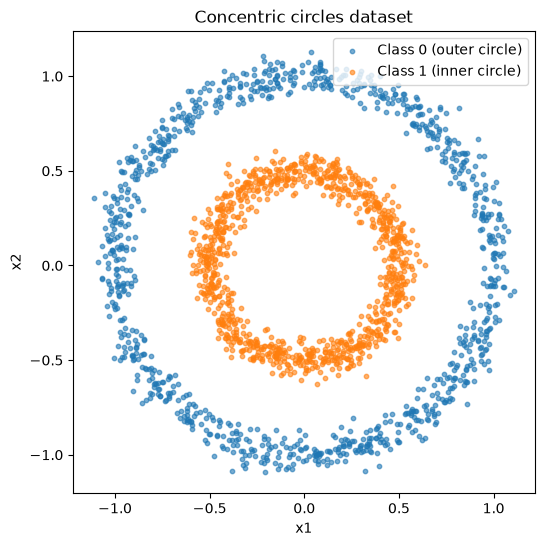

In [24]:
import matplotlib.pyplot as plt

rng_data = np.random.default_rng(SEED + 100 * RUN + 3)
# class 1: inner circle, radius 0.5
theta_inner = rng_data.uniform(0.0, 2.0 * np.pi, 1000)
inner = 0.5 * np.column_stack([np.cos(theta_inner), np.sin(theta_inner)])
# class 0: outer circle, radius 1.0
theta_outer = rng_data.uniform(0.0, 2.0 * np.pi, 1000)
outer = 1.0 * np.column_stack([np.cos(theta_outer), np.sin(theta_outer)])
inner += rng_data.normal(0.0, 0.05, size=inner.shape)
outer += rng_data.normal(0.0, 0.05, size=outer.shape)
X_circ = np.vstack([outer, inner])
y_circ = np.concatenate([
    np.zeros(1000, dtype=np.int64),
    np.ones(1000, dtype=np.int64),
])

rng_split_c = np.random.default_rng(SEED + 100 * RUN + 0)
train_idx_c, val_idx_c, test_idx_c = stratified_split(y_circ, rng_split_c, 600, 200, 200)
X_train_c = X_circ[train_idx_c]
y_train_c = y_circ[train_idx_c]
X_val_c = X_circ[val_idx_c]
y_val_c = y_circ[val_idx_c]
X_test_c = X_circ[test_idx_c]
y_test_c = y_circ[test_idx_c]

print("X_circ:", X_circ.shape, "y_circ:", y_circ.shape)
print("train counts:", np.bincount(y_train_c, minlength=2))
print("val counts:  ", np.bincount(y_val_c, minlength=2))
print("test counts: ", np.bincount(y_test_c, minlength=2))
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(
    X_circ[y_circ == 0, 0], X_circ[y_circ == 0, 1],
    s=10, alpha=0.6, label="Class 0 (outer circle)"
)
ax.scatter(
    X_circ[y_circ == 1, 0], X_circ[y_circ == 1, 1],
    s=10, alpha=0.6, label="Class 1 (inner circle)"
)
ax.set_aspect("equal")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Concentric circles dataset")
ax.legend()
plt.show()

In [30]:
activations = {
    "ReLU": ReLU(),
    "Tanh": Tanh(),
    "Sigmoid": Sigmoid(),
    "Identity": Identity(),
}

architecture = [2, 16, 16, 1]
results = []
histories = {}
models = {}
USE_WANDB_CIRCLES = True
if USE_WANDB_CIRCLES:
    import wandb

for name, activation in activations.items():
    run = None
    if USE_WANDB_CIRCLES:
        run = wandb.init(
            project="smai-a4-mlp",
            name=f"circles-{name.lower()}",
            config={
                "dataset": "concentric-circles",
                "activation": name,
                "architecture": architecture,
                "lr": 0.5,
                "batch_size": 32,
                "epochs": 600,
                "grad_accumulation_steps": 1,
                "early_stopping": False,
            },
            reinit=True,
        )
    rng_init = np.random.default_rng(SEED + 100 * RUN + 1)
    model = Model(
        [
            Linear(2, 16, activation, rng_init),
            Linear(16, 16, activation, rng_init),
            Linear(16, 1, Sigmoid(), rng_init),
        ],
        "bce",
    )
    rng_batch = np.random.default_rng(SEED + 100 * RUN + 2)
    hist = train_model(
        model,
        X_train_c, y_train_c,
        X_val_c, y_val_c,
        batch_size=32,
        grad_accumulation_steps=1,
        lr=0.5,
        epochs=600,
        rng_batch=rng_batch,
        patience=601,
        relative_loss_threshold=0.01,
        wandb_run=run,
    )
    train_loss, train_acc = evaluate(model, X_train_c, y_train_c)
    val_loss, val_acc = evaluate(model, X_val_c, y_val_c)
    test_loss, test_acc = evaluate(model, X_test_c, y_test_c)
    results.append({
        "activation": name,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "test_loss": test_loss,
        "test_acc": test_acc,
    })
    histories[name] = hist
    models[name] = model
    if run is not None:
        run.log({"test/loss": test_loss, "test/acc": test_acc})
        run.finish()

print("Architecture:", " -> ".join(map(str, architecture)),"| output: Sigmoid | loss: BCE")
print()
print(f"{'Activation':<10}{'Train acc':>12}{'Val acc':>12}{'Test acc':>12}")
for r in results:
    print(
        f"{r['activation']:<10}"
        f"{r['train_acc']:12.4f}"
        f"{r['val_acc']:12.4f}"
        f"{r['test_acc']:12.4f}"
    )

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▁▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇████
epoch/train_acc,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/train_loss,█▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/val_acc,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/val_loss,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
iter/samples_seen,▁▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
iter/train_loss,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
test/acc,▁
test/loss,▁
epoch,600
epoch/train_acc,1


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇███
epoch/train_acc,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/train_loss,█▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/val_acc,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/val_loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
iter/samples_seen,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇█████
iter/train_loss,█▆▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
test/acc,▁
test/loss,▁
epoch,600
epoch/train_acc,1


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇█████
epoch/train_acc,▁▃██████████████████████████████████████
epoch/train_loss,███▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/val_acc,▁▃██████████████████████████████████████
epoch/val_loss,██▅▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
iter/samples_seen,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▄▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▇▇▇▇▇████
iter/train_loss,█▅▅▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
test/acc,▁
test/loss,▁
epoch,600
epoch/train_acc,1


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▁▁▂▂▂▂▂▂▂▃▃▃▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇█████
epoch/train_acc,▅▅▅▄▄▇▂▅▃▅█▄▆█▅▄▅▃▂▅▄▅▄▄▆▆▃▆▅▅▆▃█▁▅▄▁▂▅▅
epoch/train_loss,▁▁▁▆▇▂▂▂▁▄▂▂▄▄▆▄▁▅▂▆▁▁▁▁▃▅▃▂█▃▁▁▂▄▃▄▃▁▄▃
epoch/val_acc,▂▅▅▅▄▁█▅▅▅▃█▆▁▅▅▃▅▅▅▅▆▆▄▅▅▅▅▅▅▅▅▅▃▁▆▅▅▅▅
epoch/val_loss,▁█▅▃▃▇▃▃▅▃▅▄▃▃▄▅▄▄▅▅▄▄▄▃▃▄▃▄▄▄▃▄▃▃▃▃▄▄▄▄
iter/samples_seen,▁▂▂▂▂▂▃▃▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▇▇▇▇▇▇▇▇▇▇▇███
iter/train_loss,▃▄▄█▆▅▄▅▅▅▂▃█▄▅▆▄▄▅▆▅▄▄▆▄▅▆▄▅▅▁▇█▅▅▆▅▆▄▄
test/acc,▁
test/loss,▁
epoch,600
epoch/train_acc,0.5


Architecture: 2 -> 16 -> 16 -> 1 | output: Sigmoid | loss: BCE

Activation   Train acc     Val acc    Test acc
ReLU            1.0000      1.0000      1.0000
Tanh            1.0000      1.0000      1.0000
Sigmoid         1.0000      1.0000      1.0000
Identity        0.5000      0.5000      0.5000


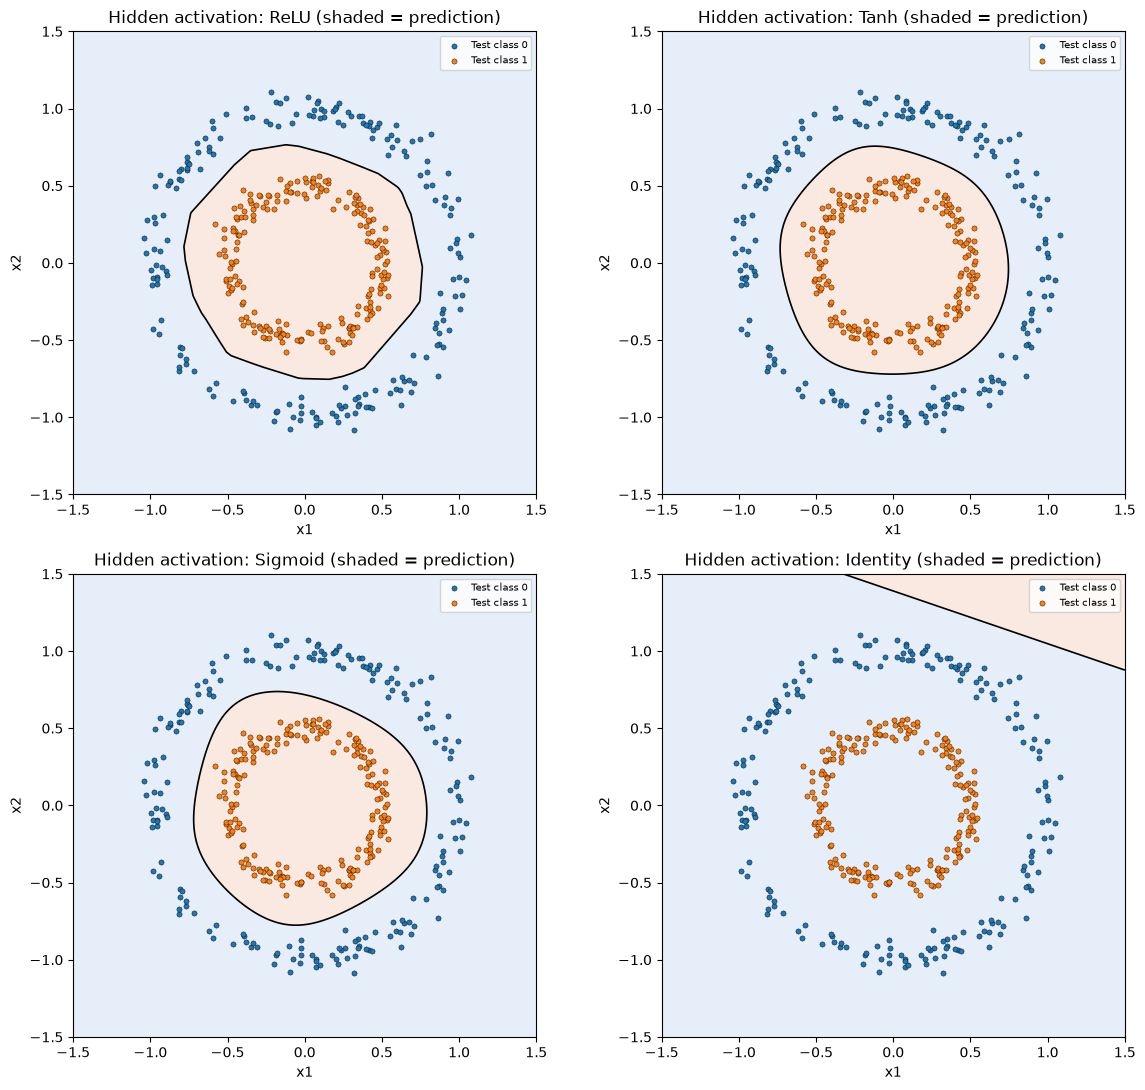

In [31]:
xx, yy = np.meshgrid(
    np.linspace(-1.5, 1.5, 300),
    np.linspace(-1.5, 1.5, 300),
)
grid = np.column_stack([xx.ravel(), yy.ravel()])
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    probs = model.predict(grid).reshape(xx.shape)
    pred = (probs >= 0.5).astype(np.int64)
    ax.contourf(
        xx, yy, pred,
        levels=[-0.5, 0.5, 1.5],
        colors=["#dce9f7", "#f7e0d5"],
        alpha=0.7,
    )
    ax.contour(
        xx, yy, probs,
        levels=[0.5],
        colors="k",
        linewidths=1.2,
    )
    ax.scatter(
        X_test_c[y_test_c == 0, 0], X_test_c[y_test_c == 0, 1],
        s=14, c="tab:blue", edgecolors="k", linewidths=0.3,
        label="Test class 0",
    )
    ax.scatter(
        X_test_c[y_test_c == 1, 0], X_test_c[y_test_c == 1, 1],
        s=14, c="tab:orange", edgecolors="k", linewidths=0.3,
        label="Test class 1",
    )
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f"Hidden activation: {name} (shaded = prediction)")
    ax.legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

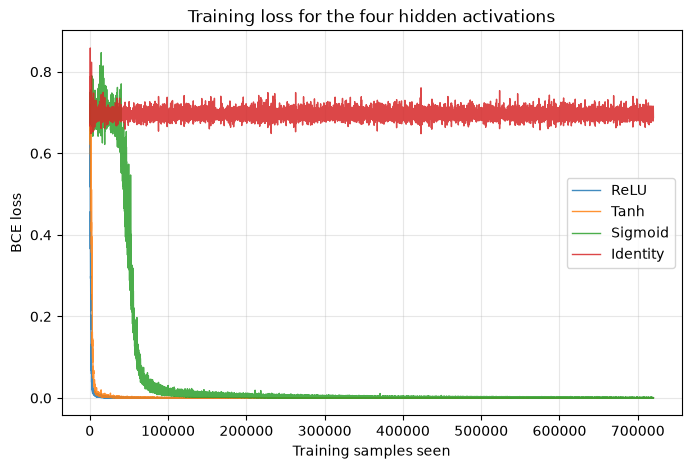

In [32]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in activations:
    h = histories[name]
    ax.plot(
        h["samples_seen"],
        h["iter_loss"],
        label=name,
        linewidth=1.0,
        alpha=0.85,
    )
ax.set_xlabel("Training samples seen")
ax.set_ylabel("BCE loss")
ax.set_title("Training loss for the four hidden activations")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

only the identify activation fails from the above run, with linear hidden layers the network remains the same map followed by a monotone sigmoid, so its decision boundary is a single straight line that cannot enclose the inner circle, reaching only 50% accuracy with test BCE of about 0.69. and form others relu and tanh learned the circulat boundary almost immdiately where as signmoid takes some time to converge but all of them ready 100% accuracy.

In [13]:
# a fixed tiny network for gradient check
rng_init_check = np.random.default_rng(SEED + 100 * RUN +1)
rng_input_check = np.random.default_rng(12345)
check_model = Model(
    [
        Linear(2,3,Tanh(),rng_init_check),
        Linear(3,2,Identity(),rng_init_check),
    ],
    "mse",
)
X_check = rng_input_check.normal(size=(4,2))
y_check = rng_input_check.normal(size=(4,2))
n_params = sum(layer.W.size + layer.b.size for layer in check_model.layers)
print("architecture: 2->3->2 (tanh hidden and identity output)")
print("loss: MSE")
print("weight init seed:", SEED+100*RUN+1)
print("Input-batch seed: 12345")
print("Batch size:", X_check.shape[0])
print("Input/target shapes:", X_check.shape, y_check.shape)
print("Number of parameters:", n_params)
print("Output shape:", check_model.forward(X_check).shape)

architecture: 2->3->2 (tanh hidden and identity output)
loss: MSE
weight init seed: 1037
Input-batch seed: 12345
Batch size: 4
Input/target shapes: (4, 2) (4, 2)
Number of parameters: 17
Output shape: (4, 2)


In [14]:
def param_grad_pairs(model):
    for layer in model.layers:
        yield layer.W, layer.dW
        yield layer.b, layer.db

def numerical_gradient(model, X, y, eps):
    chunks =[]
    for param, _ in param_grad_pairs(model):
        g = np.zeros(param.size, dtype=np.float64)
        for i in range(param.size):
            old = param.flat[i]
            try:
                param.flat[i] = old + eps
                loss_plus,_ = model._loss(model.forward(X),y)

                param.flat[i] = old - eps
                loss_minus, _ = model._loss(model.forward(X),y)
            finally:
                param.flat[i] = old
            g[i] = (loss_plus - loss_minus) / (2.0*eps)
        chunks.append(g)
    return np.concatenate(chunks)

def backprop_gradient(model,X,y):
    model.zero_grad()
    out = model.forward(X)
    loss,dout = model._loss(out,y)
    model.backward(dout)
    return np.concatenate([grad.ravel() for _,grad in param_grad_pairs(model)])

In [15]:
#check the above gradients and print the table

g_bp = backprop_gradient(check_model, X_check, y_check)
eps_values = [1e-2,1e-3,1e-4,1e-5,1e-6]
print(f"{'epsilon':>10}{'max |g_num-g_bp|':>24}{'relative L2':>18}")

for eps in eps_values:
    g_num = numerical_gradient(check_model,X_check,y_check,eps)
    max_abs_err = np.max(np.abs(g_num-g_bp))
    rel_12_err=np.linalg.norm(g_num-g_bp)/max(1e-12,np.linalg.norm(g_num)+np.linalg.norm(g_bp))
    print(f"{eps:10.0e}{max_abs_err:24.6e}{rel_12_err:18.6e}")

   epsilon        max |g_num-g_bp|       relative L2
     1e-02            2.001349e-05      1.745323e-05
     1e-03            2.001415e-07      1.745351e-07
     1e-04            2.002327e-09      1.745367e-09
     1e-05            2.613001e-11      3.011824e-11
     1e-06            1.485511e-10      1.786357e-10


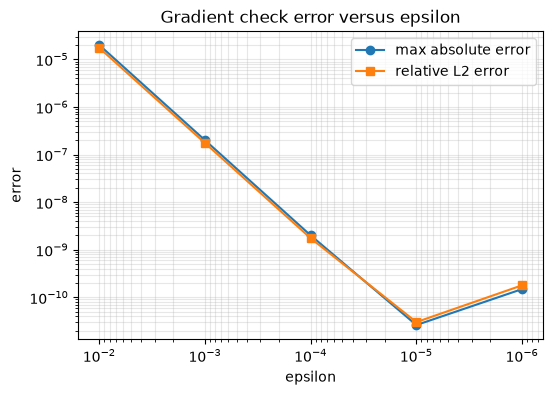

In [16]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
eps_plot = [row[0] for row in rows] if "rows" in globals() else eps_values
abs_errors = []
rel_errors = []
for eps in eps_values:
    g_num = numerical_gradient(check_model, X_check, y_check, eps)
    abs_errors.append(np.max(np.abs(g_num - g_bp)))
    rel_errors.append(
        np.linalg.norm(g_num - g_bp)
        / max(1e-12, np.linalg.norm(g_num) + np.linalg.norm(g_bp))
    )

ax.loglog(eps_values, abs_errors, marker="o", label="max absolute error")
ax.loglog(eps_values, rel_errors, marker="s", label="relative L2 error")
ax.invert_xaxis()
ax.set_xlabel("epsilon")
ax.set_ylabel("error")
ax.set_title("Gradient check error versus epsilon")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

In [21]:
# train multiple models on cifar dataset
def build_mlp(hidden_widths,activation,rng):
    layers=[]
    n_in=3072
    for width in hidden_widths:
        layers.append(Linear(n_in,width,activation,rng))
        n_in = width
    layers.append(Linear(n_in,10,Identity(),rng))
    return Model(layers,"cce")


def count_parameters(model):
    return sum(layer.W.size + layer.b.size for layer in model.layers)

architectures = [
    ("cifar-1h-64-relu",           [64],         ReLU(),    "ReLU"),
    ("cifar-1h-128-relu",          [128],        ReLU(),    "ReLU"),
    ("cifar-2h-256-128-relu",      [256, 128],   ReLU(),    "ReLU"),
    ("cifar-2h-128-128-tanh",      [128, 128],   Tanh(),    "Tanh"),
    ("cifar-3h-32-32-32-sigmoid",  [32, 32, 32], Sigmoid(), "Sigmoid"),
]

In [22]:
BATCH_SIZE = 64
EPOCHS = 30
LR = 0.02
GRAD_ACCUM = 1
PATIENCE = 5
REL_THRESHOLD = 0.01
USE_WANDB_CIFAR = True

results = []
histories = {}
models = {}

if USE_WANDB_CIFAR:
    import wandb

for name, widths,activation,act_name in architectures:
    run_name = f"{name}-lr{LR:.2f}"
    rng_init = np.random.default_rng(SEED+100*RUN+1)
    model = build_mlp(widths,activation,rng_init)
    n_params=count_parameters(model)
    run = None
    if USE_WANDB_CIFAR:
        run = wandb.init(
            project="smai-a4-mlp",
            name=run_name,
            config={
                "dataset": "cifar10",
                "architecture": [3072] + widths + [10],
                "hidden_widths": widths,
                "activation": act_name,
                "n_parameters": n_params,
                "lr": LR,
                "batch_size": BATCH_SIZE,
                "epochs": EPOCHS,
                "grad_accumulation_steps": GRAD_ACCUM,
                "early_stopping": True,
                "patience": PATIENCE,
                "relative_loss_threshold": REL_THRESHOLD,
            },
            reinit=True,
        )

    rng_batch = np.random.default_rng(SEED+100*RUN+2)
    hist = train_model(
        model,
        X_train, y_train,
        X_val, y_val,
        batch_size=BATCH_SIZE,
        grad_accumulation_steps=GRAD_ACCUM,
        lr=LR,
        epochs=EPOCHS,
        rng_batch=rng_batch,
        patience=PATIENCE,
        relative_loss_threshold=REL_THRESHOLD,
        wandb_run=run,
    )
    train_loss, train_acc = evaluate(model,X_train,y_train)
    val_loss, val_acc = evaluate(model,X_val,y_val)
    test_loss, test_acc = evaluate(model,X_test,y_test)
    results.append({
        "name": name,
        "run_name": run_name,
        "widths": widths,
        "activation": act_name,
        "n_params": n_params,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "test_loss": test_loss,
        "test_acc": test_acc,
        "stopped_epoch": hist["stopped_epoch"],
    })
    histories[name] = hist
    models[name] = model
    if run is not None:
        run.log({
            "final/train_loss": train_loss,
            "final/train_acc": train_acc,
            "final/val_loss": val_loss,
            "final/val_acc": val_acc,
            "final/test_loss": test_loss,
            "final/test_acc": test_acc,
            "final/n_params": n_params,
        })
        run.finish()
    print(
        f"{run_name}: params={n_params:,}, "
        f"stopped_epoch={hist['stopped_epoch']}, "
        f"train_acc={train_acc:.4f}, "
        f"val_acc={val_acc:.4f}, "
        f"test_acc={test_acc:.4f}"
    )

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Early stopping at epoch 10


epoch,▁▂▃▃▄▅▆▆▇█
epoch/train_acc,▁▃▄▅▆▅▇▇██
epoch/train_loss,█▆▅▄▃▄▂▂▁▁
epoch/val_acc,▁▅▅▆▇▅█▇██
epoch/val_loss,█▄▃▂▁▄▁▁▁▁
final/n_params,▁
final/test_acc,▁
final/test_loss,▁
final/train_acc,▁
final/train_loss,▁
+4,...


cifar-1h-64-relu-lr0.02: params=197,322, stopped_epoch=10, train_acc=0.5986, val_acc=0.4907, test_acc=0.4844


Early stopping at epoch 9


...

epoch,▁▂▃▄▅▅▆▇█
epoch/train_acc,▁▃▄▄▅▅▇▇█
epoch/train_loss,█▆▅▄▄▄▂▂▁
epoch/val_acc,▁▄▅▆▇▅█▇▇
epoch/val_loss,█▅▃▂▁▄▁▂▂
final/n_params,▁
final/test_acc,▁
final/test_loss,▁
final/train_acc,▁
final/train_loss,▁
+4,...


cifar-2h-128-128-tanh-lr0.02: params=411,146, stopped_epoch=9, train_acc=0.5831, val_acc=0.4546, test_acc=0.4511


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
epoch/train_acc,▁▁▂▂▂▂▃▃▄▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇████
epoch/train_loss,██▇▇▆▅▅▅▄▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁
epoch/val_acc,▁▁▂▂▃▃▃▄▄▄▅▅▅▅▅▆▆▆▆▇▇▇▇███████
epoch/val_loss,██▇▇▆▅▅▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁
final/n_params,▁
final/test_acc,▁
final/test_loss,▁
final/train_acc,▁
final/train_loss,▁
+4,...


cifar-3h-32-32-32-sigmoid-lr0.02: params=100,778, stopped_epoch=30, train_acc=0.4030, val_acc=0.3755, test_acc=0.3749


In [23]:
print(f"{'Model / WandB run':<40}{'Hidden widths':<20}{'Activation':<12}{'Parameters':>12}")

for r in results:
    print(
        f"{r['run_name']:<40}"
        f"{str(r['widths']):<20}"
        f"{r['activation']:<12}"
        f"{r['n_params']:>12,}"
    )

Model / WandB run                       Hidden widths       Activation    Parameters
cifar-1h-64-relu-lr0.02                 [64]                ReLU             197,322
cifar-1h-128-relu-lr0.02                [128]               ReLU             394,634
cifar-2h-256-128-relu-lr0.02            [256, 128]          ReLU             820,874
cifar-2h-128-128-tanh-lr0.02            [128, 128]          Tanh             411,146
cifar-3h-32-32-32-sigmoid-lr0.02        [32, 32, 32]        Sigmoid          100,778


In [25]:
print()
print(f"{'Model / WandB run':<40}{'Train loss':>12}{'Train acc':>11}{'Val loss':>10}{'Val acc':>9}{'Test loss':>11}{'Test acc':>10}")

for r in results:
    print(
        f"{r['run_name']:<40}"
        f"{r['train_loss']:12.4f}"
        f"{r['train_acc']:11.4f}"
        f"{r['val_loss']:10.4f}"
        f"{r['val_acc']:9.4f}"
        f"{r['test_loss']:11.4f}"
        f"{r['test_acc']:10.4f}"
    )


Model / WandB run                         Train loss  Train acc  Val loss  Val acc  Test loss  Test acc
cifar-1h-64-relu-lr0.02                       1.1585     0.5986    1.4839   0.4907     1.4894    0.4844
cifar-1h-128-relu-lr0.02                      1.0789     0.6276    1.4653   0.4999     1.4760    0.4911
cifar-2h-256-128-relu-lr0.02                  0.9508     0.6723    1.4799   0.5014     1.5041    0.4914
cifar-2h-128-128-tanh-lr0.02                  1.2494     0.5831    1.5936   0.4546     1.6129    0.4511
cifar-3h-32-32-32-sigmoid-lr0.02              1.6752     0.4030    1.7409   0.3755     1.7584    0.3749


In [26]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

for name, model in models.items():
    model.save_to(f"models/{name}.npz")

print("Saved:", list(models))

Saved: ['cifar-1h-64-relu', 'cifar-1h-128-relu', 'cifar-2h-256-128-relu', 'cifar-2h-128-128-tanh', 'cifar-3h-32-32-32-sigmoid']


In [27]:
CIFAR10_CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

def confusion_matrix(y_true, y_pred, n_classes=10):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)
    return np.bincount(
        y_true * n_classes + y_pred,
        minlength=n_classes * n_classes,
    ).reshape(n_classes, n_classes)

def class_metrics_from_cm(cm):
    cm_int = np.asarray(cm, dtype=np.int64)
    cm = cm_int.astype(np.float64)
    n = cm.sum()
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = n - tp - fp - fn
    accuracy = (tp + tn) / n
    precision = np.divide(
        tp, tp + fp,
        out=np.zeros_like(tp),
        where=(tp + fp) != 0,
    )
    recall = np.divide(
        tp, tp + fn,
        out=np.zeros_like(tp),
        where=(tp + fn) != 0,
    )
    f1 = np.divide(
        2.0 * precision * recall,
        precision + recall,
        out=np.zeros_like(tp),
        where=(precision + recall) != 0,
    )
    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": cm_int.sum(axis=1),
    }

def predict_labels(model, X, batch_size=1024):
    preds = []
    for start in range(0, len(X), batch_size):
        logits = model.forward(X[start:start + batch_size])
        preds.append(np.argmax(logits, axis=1))
    return np.concatenate(preds)

test_preds = {}
confusions = {}
class_metrics = {}
for r in results:
    name = r["name"]
    preds = predict_labels(models[name], X_test)
    cm = confusion_matrix(y_test, preds)
    test_preds[name] = preds
    confusions[name] = cm
    class_metrics[name] = class_metrics_from_cm(cm)
print("Computed metrics for", len(confusions), "models")

Computed metrics for 5 models


In [28]:
print("Final losses and accuracies")
print(
    f"{'Model / WandB run':<40}"
    f"{'Train loss':>12}{'Train acc':>11}"
    f"{'Val loss':>10}{'Val acc':>9}"
    f"{'Test loss':>11}{'Test acc':>10}"
)

for r in results:
    print(
        f"{r['run_name']:<40}"
        f"{r['train_loss']:12.4f}"
        f"{r['train_acc']:11.4f}"
        f"{r['val_loss']:10.4f}"
        f"{r['val_acc']:9.4f}"
        f"{r['test_loss']:11.4f}"
        f"{r['test_acc']:10.4f}"
    )
for r in results:
    name = r["name"]
    m = class_metrics[name]
    print("\n" + "=" * 90)
    print("Model:", r["run_name"])
    print(
        f"{'Class':<12}{'Accuracy':>10}{'Precision':>11}"
        f"{'Recall':>10}{'F1':>10}{'Support':>9}"
    )
    for k, cls in enumerate(CIFAR10_CLASSES):
        print(
            f"{cls:<12}"
            f"{m['accuracy'][k]:10.4f}"
            f"{m['precision'][k]:11.4f}"
            f"{m['recall'][k]:10.4f}"
            f"{m['f1'][k]:10.4f}"
            f"{int(m['support'][k]):9d}"
        )
    print(
        f"{'Mean':<12}"
        f"{m['accuracy'].mean():10.4f}"
        f"{m['precision'].mean():11.4f}"
        f"{m['recall'].mean():10.4f}"
        f"{m['f1'].mean():10.4f}"
        f"{'':>9}"
    )
    print("Total support:", int(m["support"].sum()))

Final losses and accuracies
Model / WandB run                         Train loss  Train acc  Val loss  Val acc  Test loss  Test acc
cifar-1h-64-relu-lr0.02                       1.1585     0.5986    1.4839   0.4907     1.4894    0.4844
cifar-1h-128-relu-lr0.02                      1.0789     0.6276    1.4653   0.4999     1.4760    0.4911
cifar-2h-256-128-relu-lr0.02                  0.9508     0.6723    1.4799   0.5014     1.5041    0.4914
cifar-2h-128-128-tanh-lr0.02                  1.2494     0.5831    1.5936   0.4546     1.6129    0.4511
cifar-3h-32-32-32-sigmoid-lr0.02              1.6752     0.4030    1.7409   0.3755     1.7584    0.3749

Model: cifar-1h-64-relu-lr0.02
Class         Accuracy  Precision    Recall        F1  Support
airplane        0.9097     0.5469    0.5633    0.5550     1200
automobile      0.9130     0.5613    0.5950    0.5777     1200
bird            0.8794     0.3804    0.3275    0.3520     1200
cat             0.8749     0.3288    0.2408    0.2780     1200
d

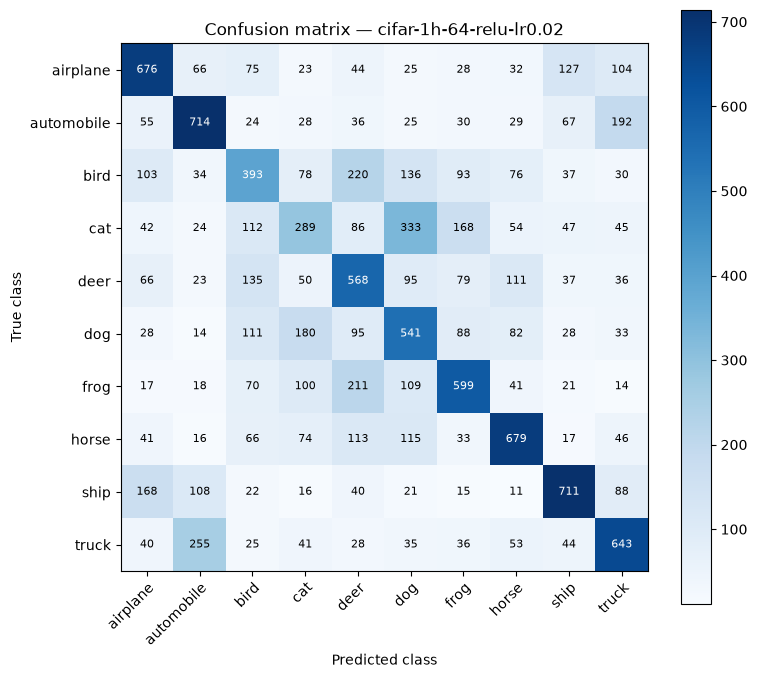

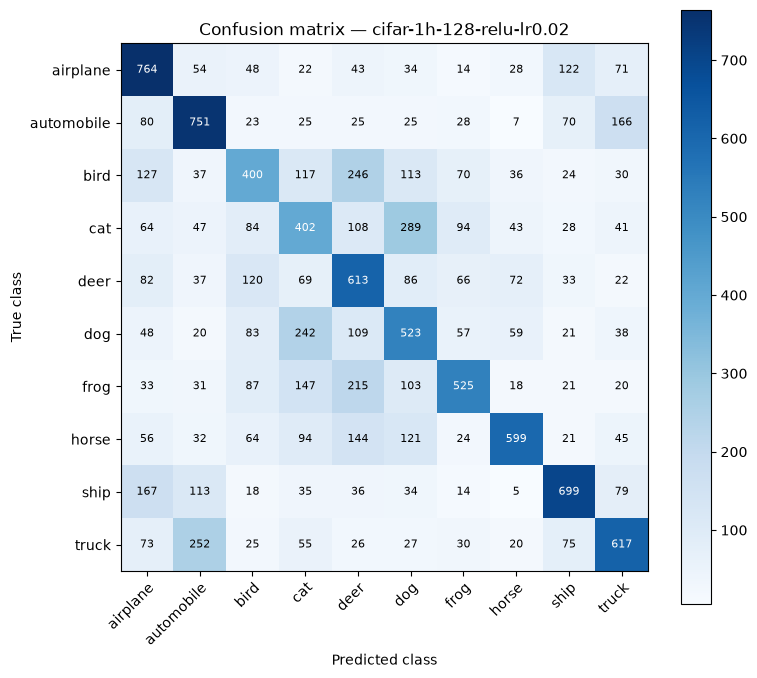

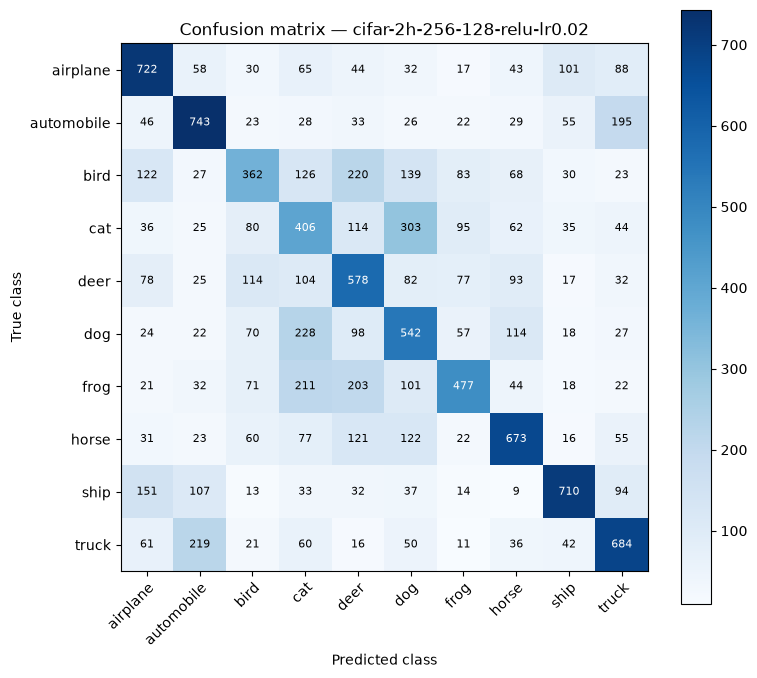

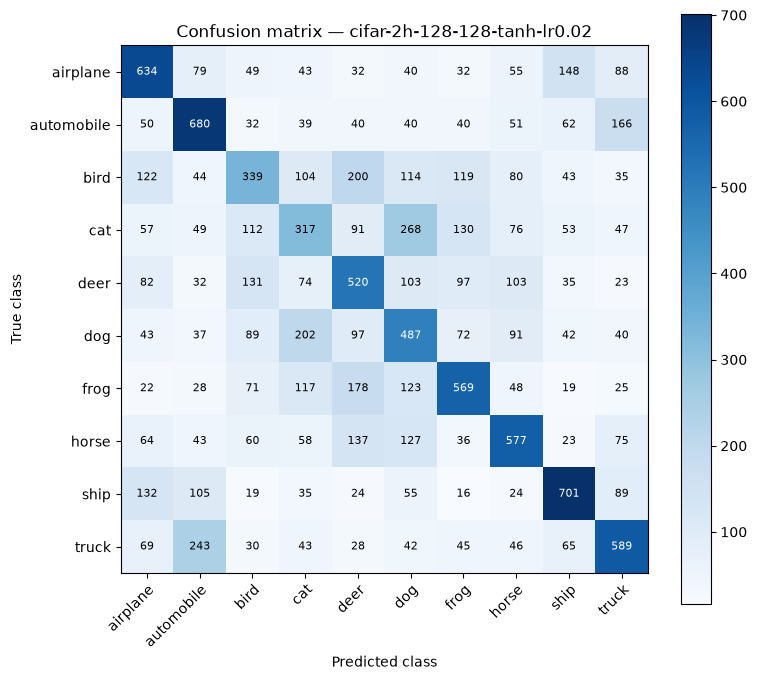

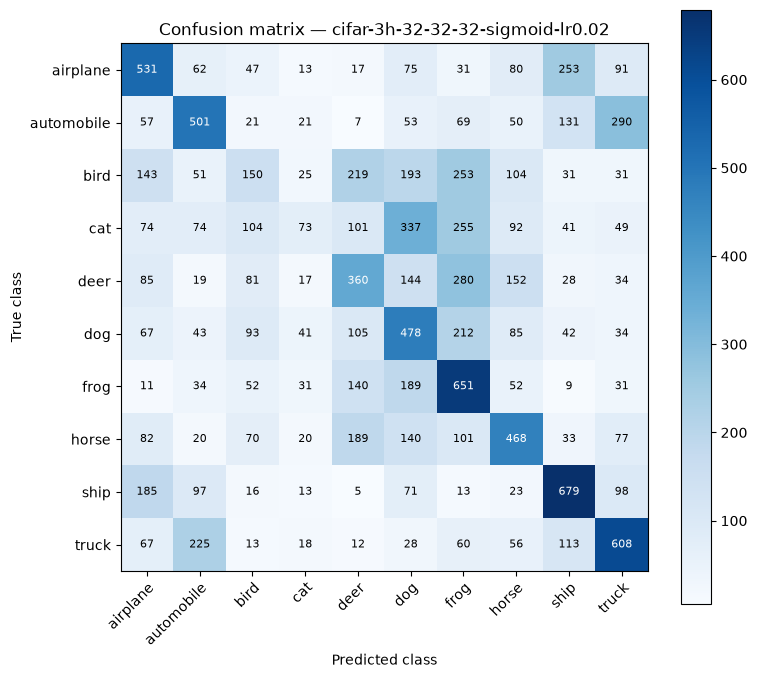

In [29]:
def plot_confusion_matrix(cm, title):
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    fig.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(10),
        yticks=np.arange(10),
        xticklabels=CIFAR10_CLASSES,
        yticklabels=CIFAR10_CLASSES,
        xlabel="Predicted class",
        ylabel="True class",
        title=title,
    )
    plt.setp(ax.get_xticklabels(),rotation=45,ha="right",rotation_mode="anchor")
    threshold = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, f"{cm[i, j]:d}",
                ha="center",
                va="center",
                color="white" if cm[i, j] > threshold else "black",
                fontsize=8,
            )
    fig.tight_layout()
    plt.show()

for r in results:
    plot_confusion_matrix(
        confusions[r["name"]],
        f"Confusion matrix — {r['run_name']}",
    )

## Most confused classes and easiest classes
The most frequent confuision is cat <-> dog in all model variants while truck<->automobile is also large. the easiest is ship with highest f1 in every model followed by automobile,horse and airplane. These results are consistent and expected as cats and dogs share fur texture and similar shapes and trucks and automobiles often share a lot of background features such as roads and other which the easier classes such as ships and horses have more distinct outlines.

## Depth, width, activation, overfitting, and model choice
when i increased width from 64 to 128 the val acc went from 49.07% to 49.99% and test from 48.44% to 49.11%, but the bigger 2h-256-128 model only gave 50.14% val and 49.14% test with almost double the params and a much bigger train-val gap (17.1 vs 12.8 percentage points). relu was clearly the best at these settings, tanh got only 45.46% val and the deep sigmoid model just 37.55% and was underfitting with only a 2.8 point gap. i would choose cifar-1h-128-relu because its val acc is only 0.15 points below the best while using less than half the params of the big model and overfitting less.

## Why class-wise accuracy is high but recall is low

the class wise accuracy is high because every class has only 1200 positives but 10800 negatives so the TN term dominates the (TP+TN)/12000 formula. for example the sigmoid model's cat class has 0.8895 accuracy but only 0.0608 recall, it finds only 73 of the 1200 cats but correctly rejecting the other classes keeps the accuracy high. so recall and f1 show the weak classes much better than class wise accuracy.

## High precision with low recall

yes, in cifar-1h-128-relu horse has precision 0.675 but recall only 0.499, so when it predicts horse it is mostly correct but it misses about half of the 1200 horses, many going to deer or dog. this means the model is conservative for horse, it avoids false horse predictions but creates many false negatives. the opposite also happens, airplane has recall 0.637 but precision only 0.511 so it finds many airplanes but also over predicts them.


In [31]:
sorted_results = sorted(results, key=lambda r: r["n_params"])
print(
    f"{'Model / WandB run':<40}"
    f"{'Parameters':>12}"
    f"{'Val acc':>10}"
    f"{'Test acc':>10}"
)

for r in sorted_results:
    print(
        f"{r['run_name']:<40}"
        f"{r['n_params']:>12,}"
        f"{r['val_acc']:10.4f}"
        f"{r['test_acc']:10.4f}"
    )

Model / WandB run                         Parameters   Val acc  Test acc
cifar-3h-32-32-32-sigmoid-lr0.02             100,778    0.3755    0.3749
cifar-1h-64-relu-lr0.02                      197,322    0.4907    0.4844
cifar-1h-128-relu-lr0.02                     394,634    0.4999    0.4911
cifar-2h-128-128-tanh-lr0.02                 411,146    0.4546    0.4511
cifar-2h-256-128-relu-lr0.02                 820,874    0.5014    0.4914


In [32]:
best_val = max(r["val_acc"] for r in results)
threshold = best_val - 0.01
eligible = [
    (i, r) for i, r in enumerate(results)
    if r["val_acc"] >= threshold
]

eligible.sort(key=lambda item: (item[1]["n_params"], -item[1]["val_acc"], item[0]))
selected = eligible[0][1]
print("Best validation accuracy:", f"{best_val:.4f}")
print("1 percentage point below best:", f"{threshold:.4f}")
print("\nEligible models:")

for _, r in sorted(eligible, key=lambda item: item[1]["n_params"]):
    print(
        f"  {r['run_name']}: "
        f"params={r['n_params']:,}, "
        f"val={r['val_acc']:.4f}, "
        f"test={r['test_acc']:.4f}"
    )

print("\nSelected:", selected["run_name"])
print("Parameters:", f"{selected['n_params']:,}")
print("Validation accuracy:", f"{selected['val_acc']:.4f}")
print("Test accuracy:", f"{selected['test_acc']:.4f}")

Best validation accuracy: 0.5014
1 percentage point below best: 0.4914

Eligible models:
  cifar-1h-128-relu-lr0.02: params=394,634, val=0.4999, test=0.4911
  cifar-2h-256-128-relu-lr0.02: params=820,874, val=0.5014, test=0.4914

Selected: cifar-1h-128-relu-lr0.02
Parameters: 394,634
Validation accuracy: 0.4999
Test accuracy: 0.4911


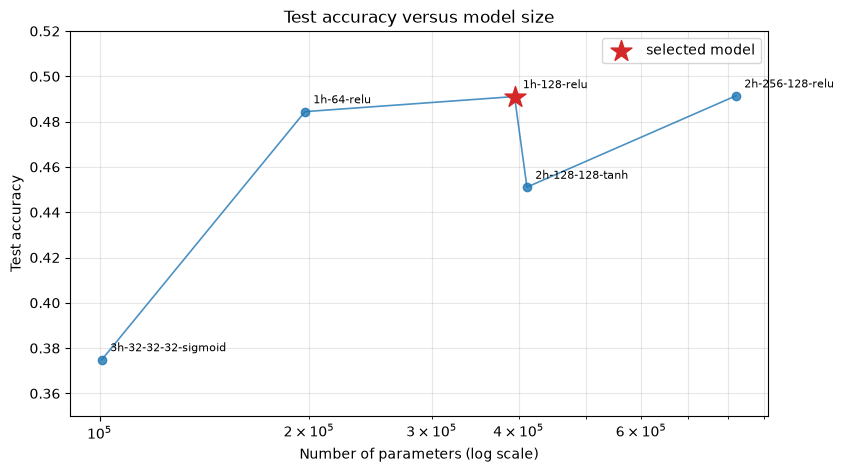

In [33]:
fig, ax = plt.subplots(figsize=(9, 5))
params = [r["n_params"] for r in sorted_results]
test_acc = [r["test_acc"] for r in sorted_results]
ax.plot(params,test_acc,marker="o",linewidth=1.2,alpha=0.8)

for r in sorted_results:
    short_name = r["name"].replace("cifar-", "")
    ax.annotate(
        short_name,
        (r["n_params"], r["test_acc"]),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=8,
    )
ax.scatter(
    [selected["n_params"]],
    [selected["test_acc"]],
    marker="*",
    s=250,
    color="tab:red",
    label="selected model",
    zorder=5,
)

ax.set_xscale("log")
ax.set_xlabel("Number of parameters (log scale)")
ax.set_ylabel("Test accuracy")
ax.set_title("Test accuracy versus model size")
ax.grid(True, which="both", alpha=0.3)
ax.set_ylim(0.35, 0.52)
ax.legend()
plt.show()

In [34]:
selected_model = models[selected["name"]]
selected_model.save_to("models/selected_mlp.npz")
selected_config = {
    "run_name": selected["run_name"],
    "hidden_widths": selected["widths"],
    "activation": selected["activation"],
    "architecture": [3072] + selected["widths"] + [10],
    "n_params": selected["n_params"],
    "lr": LR,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "grad_accumulation_steps": GRAD_ACCUM,
    "patience": PATIENCE,
    "relative_loss_threshold": REL_THRESHOLD,
    "val_acc": selected["val_acc"],
    "test_acc": selected["test_acc"],
}
print(selected_config)

{'run_name': 'cifar-1h-128-relu-lr0.02', 'hidden_widths': [128], 'activation': 'ReLU', 'architecture': [3072, 128, 10], 'n_params': 394634, 'lr': 0.02, 'batch_size': 64, 'epochs': 30, 'grad_accumulation_steps': 1, 'patience': 5, 'relative_loss_threshold': 0.01, 'val_acc': np.float64(0.4999166666666667), 'test_acc': np.float64(0.4910833333333333)}


the curve becomes almost flatt after 1h-128, going from 394,634 to 820,874 params only moved val acc from 49.99% to 50.14% and test from 49.11% to 49.14%. the 1h-64 model is just outside the 1% band (49.07% vs the 49.14% cutoff with the 1% band), so 1h-128 is the smallest eligible model. i also tried the deeper 2h-128-128 tanh model but it did worse (45.46% val) and the 100k sigmoid model underfit at 37.55%, so neither helped. so i select cifar-1h-128-relu with 394,634 params and 49.11% test accuracy

# IOCNN

In [37]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from datasets import load_dataset

ds14 = load_dataset("uoft-cs/cifar10")
X_train_14 = np.empty((50_000, 32, 32, 3), dtype=np.uint8)
X_test_14 = np.empty((10_000, 32, 32, 3), dtype=np.uint8)
for i, img in enumerate(ds14["train"]["img"]):
    X_train_14[i] = np.asarray(img, dtype=np.uint8)
    
for i, img in enumerate(ds14["test"]["img"]):
    X_test_14[i] = np.asarray(img, dtype=np.uint8)

y_train_14 = np.asarray(ds14["train"]["label"], dtype=np.int64)
y_test_14 = np.asarray(ds14["test"]["label"], dtype=np.int64)
X_train_14 = X_train_14.reshape(50_000, 3072).astype(np.float64)
X_test_14 = X_test_14.reshape(10_000, 3072).astype(np.float64)
X_train_14 /= 255.0
X_test_14 /= 255.0

mean14 = X_train_14.mean(axis=0)
std14 = X_train_14.std(axis=0)
std14[std14 == 0.0] = 1.0

X_train_14 -= mean14
X_train_14 /= std14
X_test_14 -= mean14
X_test_14 /= std14
X_train_14 = X_train_14.astype(np.float32)
X_test_14 = X_test_14.astype(np.float32)

train_dataset = TensorDataset(
    torch.from_numpy(X_train_14),
    torch.from_numpy(y_train_14),
)
test_dataset = TensorDataset(
    torch.from_numpy(X_test_14),
    torch.from_numpy(y_test_14),
)

g14 = torch.Generator().manual_seed(SEED + 2)
train_loader = DataLoader(
    train_dataset,
    batch_size=selected_config["batch_size"],
    shuffle=True,
    generator=g14,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
)

print("X_train_14:", X_train_14.shape, X_train_14.dtype)
print("X_test_14: ", X_test_14.shape, X_test_14.dtype)
print("train batches:", len(train_loader))
print("test batches: ", len(test_loader))

X_train_14: (50000, 3072) float32
X_test_14:  (10000, 3072) float32
train batches: 782
test batches:  40


In [38]:
class TorchMLP(nn.Module):
    def __init__(self, hidden_widths, activation_name):
        super().__init__()
        dims = [3072] + hidden_widths + [10]
        self.layers = nn.ModuleList([
            nn.Linear(dims[i], dims[i + 1])
            for i in range(len(dims) - 1)
        ])
        self.activation_name = activation_name
        self.reset_parameters()

    def reset_parameters(self):
        for i, layer in enumerate(self.layers):
            if i < len(self.layers) - 1:
                if self.activation_name == "relu":
                    std = (2.0 / layer.in_features) ** 0.5
                else:
                    std = (1.0 / layer.in_features) ** 0.5
            else:
                std = (1.0 / layer.in_features) ** 0.5
            nn.init.normal_(layer.weight, mean=0.0, std=std)
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        for i, layer in enumerate(self.layers):
            x = layer(x)
            if i < len(self.layers) - 1:
                if self.activation_name == "relu":
                    x = torch.relu(x)
                elif self.activation_name == "tanh":
                    x = torch.tanh(x)
                elif self.activation_name == "sigmoid":
                    x = torch.sigmoid(x)
        return x

class IOCMLP(nn.Module):
    def __init__(self, hidden_widths):
        super().__init__()
        dims = [3072] + hidden_widths + [10]
        self.layers = nn.ModuleList([
            nn.Linear(dims[i], dims[i + 1])
            for i in range(len(dims) - 1)
        ])
        self.reset_parameters()

    def reset_parameters(self):
        first = self.layers[0]
        std = (1.0 / first.in_features) ** 0.5
        nn.init.normal_(first.weight, mean=0.0, std=std)
        nn.init.zeros_(first.bias)
        for layer in self.layers[1:]:
            bound = 2.0 / layer.in_features
            nn.init.uniform_(layer.weight, 0.0, bound)
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        for i, layer in enumerate(self.layers):
            x = layer(x)
            if i < len(self.layers) - 1:
                x = F.elu(x)
        return x


@torch.no_grad()
def project_ioc_weights(model):
    for layer in model.layers[1:]:
        w = layer.weight.data
        w.copy_(torch.where(w < 0.0, torch.exp(w - 5.0), w))
        assert w.min().item() >= 0.0

def count_parameters_torch(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def build_models(hidden_widths, mlp_activation, seed):
    torch.manual_seed(seed + 1)
    mlp = TorchMLP(hidden_widths, mlp_activation)
    ioc = IOCMLP(hidden_widths)
    with torch.no_grad():
        ioc.layers[0].weight.copy_(mlp.layers[0].weight)
        ioc.layers[0].bias.copy_(mlp.layers[0].bias)
    return mlp, ioc

In [39]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
mlp, ioc = build_models(
    selected_config["hidden_widths"],
    selected_config["activation"].lower(),
    SEED,
)
mlp = mlp.to(device)
ioc = ioc.to(device)

print("PyTorch MLP parameters:", f"{count_parameters_torch(mlp):,}")
print("PyTorch IOC parameters:", f"{count_parameters_torch(ioc):,}")
print("NumPy MLP parameters:  ", f"{selected_config['n_params']:,}")
print(
    "first-layer max difference:",
    (mlp.layers[0].weight - ioc.layers[0].weight).abs().max().item(),
)
print(
    "IOC min weight in layers 2+:",
    min(layer.weight.min().item() for layer in ioc.layers[1:]),
)
xb = torch.from_numpy(X_test_14[:5]).to(device)
with torch.no_grad():
    print("MLP logits shape:", mlp(xb).shape)
    print("IOC logits shape:", ioc(xb).shape)

device: cpu
PyTorch MLP parameters: 394,634
PyTorch IOC parameters: 394,634
NumPy MLP parameters:   394,634
first-layer max difference: 0.0
IOC min weight in layers 2+: 2.747960388660431e-05
MLP logits shape: torch.Size([5, 10])
IOC logits shape: torch.Size([5, 10])


In [40]:
print("PyTorch MLP parameters:", f"{count_parameters_torch(mlp):,}")
print("PyTorch IOC parameters:", f"{count_parameters_torch(ioc):,}")
print("NumPy MLP parameters:  ", f"{selected_config['n_params']:,}")

assert count_parameters_torch(mlp) == selected_config["n_params"]
with torch.no_grad():
    for numpy_layer, torch_layer in zip(selected_model.layers, mlp.layers):
        torch_layer.weight.copy_(
            torch.from_numpy(
                np.ascontiguousarray(numpy_layer.W.T)
            ).to(dtype=torch.float32, device=device)
        )
        torch_layer.bias.copy_(
            torch.from_numpy(numpy_layer.b).to(
                dtype=torch.float32, device=device
            )
        )

x5_np = X_test[:5]
logits_numpy = selected_model.forward(x5_np)
x5_torch = torch.from_numpy(x5_np).float().to(device)
with torch.no_grad():
    logits_torch = mlp(x5_torch).cpu().numpy()
max_diff = np.max(np.abs(logits_numpy - logits_torch))

print("NumPy logits shape:  ", logits_numpy.shape)
print("PyTorch logits shape:", logits_torch.shape)
print("Maximum absolute difference:", max_diff)

assert max_diff < 1e-4

print("NumPy logits first row:  ", logits_numpy[0])
print("PyTorch logits first row:", logits_torch[0])

PyTorch MLP parameters: 394,634
PyTorch IOC parameters: 394,634
NumPy MLP parameters:   394,634
NumPy logits shape:   (5, 10)
PyTorch logits shape: (5, 10)
Maximum absolute difference: 1.9034809959350696e-06
NumPy logits first row:   [ 1.9098139  -0.87318493  1.16787516 -0.56642675  0.18058212 -0.74549635
 -1.94271767 -1.61336442 -0.7013829  -0.04798465]
PyTorch logits first row: [ 1.909814   -0.8731845   1.1678748  -0.56642675  0.18058234 -0.7454961
 -1.9427183  -1.6133645  -0.7013827  -0.04798439]


In [41]:
rng_convex = np.random.default_rng(SEED + 123)

idx1 = rng_convex.integers(0, len(X_test_14), size=100)
idx2 = rng_convex.integers(0, len(X_test_14), size=100)

x1 = torch.from_numpy(X_test_14[idx1]).to(device)
x2 = torch.from_numpy(X_test_14[idx2]).to(device)

@torch.no_grad()
def count_convexity_violations(model, x1, x2, tol=1e-4):
    f1 = model(x1)
    f2 = model(x2)
    fmid = model(0.5 * x1 + 0.5 * x2)
    rhs = 0.5 * f1 + 0.5 * f2 + tol
    violations = (fmid > rhs).any(dim=1)
    return int(violations.sum().item())

mlp_violations = count_convexity_violations(mlp, x1, x2)
ioc_violations = count_convexity_violations(ioc, x1, x2)

print("MLP violations out of 100 pairs:", mlp_violations)
print("IOC-NN violations out of 100 pairs:", ioc_violations)

MLP violations out of 100 pairs: 100
IOC-NN violations out of 100 pairs: 0


In [42]:
import time

def make_noisy_labels(y, p, rng):
    y_noisy = y.copy()
    n = len(y)
    n_changed = int(np.floor(p * n))
    changed = rng.permutation(n)[:n_changed]
    new_labels = rng.integers(0, 10, size=n_changed)
    y_noisy[changed] = new_labels
    return y_noisy, changed

noise_data = {}
for p in [0.0, 0.5, 1.0]:
    rng_noise = np.random.default_rng(SEED + 3)
    y_noisy, changed = make_noisy_labels(y_train_14, p, rng_noise)
    noise_data[p] = {
        "y_noisy": y_noisy,
        "changed": changed,
    }
    frac_diff = np.mean(y_noisy != y_train_14)
    print(
        f"p={p}: changed={len(changed):,}, "
        f"fraction different={frac_diff:.4f}"
    )

p=0.0: changed=0, fraction different=0.0000
p=0.5: changed=25,000, fraction different=0.4493
p=1.0: changed=50,000, fraction different=0.8992


In [43]:
@torch.no_grad()
def evaluate_torch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total = 0
    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)
        total_loss += loss.item() * len(xb)
        total_correct += (logits.argmax(dim=1) == yb).sum().item()
        total += len(xb)
    return total_loss / total, total_correct / total

def train_one_epoch(model, loader, optimizer, criterion, device, project=False):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total = 0
    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        if project:
            project_ioc_weights(model)
        total_loss += loss.item() * len(xb)
        total_correct += (logits.argmax(dim=1) == yb).sum().item()
        total += len(xb)
    return total_loss / total, total_correct / total

@torch.no_grad()
def accuracy_on_indices(model, X, y, indices, device, batch_size=1024):
    model.eval()
    correct = 0
    for start in range(0, len(indices), batch_size):
        idx = indices[start:start + batch_size]
        xb = torch.from_numpy(X[idx]).to(device)
        yb = torch.from_numpy(y[idx]).to(device)
        pred = model(xb).argmax(dim=1)
        correct += (pred == yb).sum().item()
    return correct / len(indices)

In [44]:
def train_run(
    model_name,
    model,
    train_loader,
    test_loader,
    y_noisy,
    changed_idx,
    p,
    epochs=100,
    lr=0.02,
    device="cpu",
    project=False,
    wandb_run=None,
):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    train_eval_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_train_14),torch.from_numpy(y_noisy)),
        batch_size=256,
        shuffle=False,
    )
    history = {
        "epoch": [],
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": [],
        "label_fit": [],
        "epoch_time": [],
    }
    for epoch in range(1, epochs + 1):
        start_time = time.perf_counter()
        train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device,
            project=project,
        )
        train_loss, train_acc = evaluate_torch(model, train_eval_loader, criterion, device)
        test_loss, test_acc = evaluate_torch(model, test_loader, criterion, device)
        if p == 0.0:
            label_fit = np.nan
        elif p == 1.0:
            label_fit = train_acc
        else:
            label_fit = accuracy_on_indices(
                model,
                X_train_14,
                y_noisy,
                changed_idx,
                device,
            )
        epoch_time = time.perf_counter() - start_time
        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        history["label_fit"].append(label_fit)
        history["epoch_time"].append(epoch_time)
        if wandb_run is not None:
            log_dict = {
                "epoch": epoch,
                "train/loss": train_loss,
                "train/acc": train_acc,
                "test/loss": test_loss,
                "test/acc": test_acc,
                "epoch_time_sec": epoch_time,
            }
            if p > 0.0:
                log_dict["label_fit"] = label_fit
            wandb_run.log(log_dict)
        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            print(
                f"{model_name}-p{p:g} epoch {epoch:3d}/{epochs}: "
                f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
                f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}, "
                f"label_fit={label_fit:.4f}, "
                f"time={epoch_time:.1f}s"
            )

    return history

In [45]:
EPOCHS_14 = 100
LR_14 = selected_config["lr"]
BATCH_SIZE_14 = selected_config["batch_size"]
USE_WANDB_14 = True

results_14 = {}
models_14 = {}

if USE_WANDB_14:
    import wandb

for p in [0.0, 0.5, 1.0]:
    y_noisy = noise_data[p]["y_noisy"]
    changed_idx = noise_data[p]["changed"]
    for model_name in ["mlp", "ioc"]:
        mlp_tmp, ioc_tmp = build_models(
            selected_config["hidden_widths"],
            selected_config["activation"].lower(),
            SEED,
        )
        model = mlp_tmp if model_name == "mlp" else ioc_tmp
        train_loader_p = DataLoader(
            TensorDataset(torch.from_numpy(X_train_14),torch.from_numpy(y_noisy)),
            batch_size=BATCH_SIZE_14,
            shuffle=True,
            generator=torch.Generator().manual_seed(SEED + 2),
        )
        run_name = f"{model_name}-p{p:g}"
        wandb_run = None
        if USE_WANDB_14:
            wandb_run = wandb.init(
                project="smai-a4-mlp",
                name=run_name,
                config={
                    "p": p,
                    "model": model_name,
                    "architecture": [3072] + selected_config["hidden_widths"] + [10],
                    "mlp_activation": selected_config["activation"],
                    "ioc_activation": "ELU",
                    "lr": LR_14,
                    "batch_size": BATCH_SIZE_14,
                    "epochs": EPOCHS_14,
                    "optimizer": "SGD",
                    "early_stopping": False,
                },
                reinit=True,
            )
            
        print("\n" + "=" * 70)
        print("Training", run_name)
        print("=" * 70)

        history = train_run(
            model_name=model_name,
            model=model,
            train_loader=train_loader_p,
            test_loader=test_loader,
            y_noisy=y_noisy,
            changed_idx=changed_idx,
            p=p,
            epochs=EPOCHS_14,
            lr=LR_14,
            device=device,
            project=(model_name == "ioc"),
            wandb_run=wandb_run,
        )
        if wandb_run is not None:
            wandb_run.finish()

        results_14[(model_name, p)] = history
        models_14[(model_name, p)] = model
        if p == 0.0:
            torch.save(
                model.state_dict(),
                f"models/{run_name}.pt",
            )
        print("Finished", run_name)


Training mlp-p0
mlp-p0 epoch   1/100: train_loss=1.5046, train_acc=0.4741, test_loss=1.5580, test_acc=0.4488, label_fit=nan, time=1.0s
mlp-p0 epoch  10/100: train_loss=1.1235, train_acc=0.6111, test_loss=1.4993, test_acc=0.4953, label_fit=nan, time=0.8s
mlp-p0 epoch  20/100: train_loss=1.2385, train_acc=0.6041, test_loss=1.9366, test_acc=0.4529, label_fit=nan, time=0.8s
mlp-p0 epoch  30/100: train_loss=0.8774, train_acc=0.6978, test_loss=1.8675, test_acc=0.4694, label_fit=nan, time=0.8s
mlp-p0 epoch  40/100: train_loss=0.7030, train_acc=0.7568, test_loss=1.9622, test_acc=0.4751, label_fit=nan, time=0.8s
mlp-p0 epoch  50/100: train_loss=0.5507, train_acc=0.8105, test_loss=2.0996, test_acc=0.4871, label_fit=nan, time=0.8s
mlp-p0 epoch  60/100: train_loss=0.5101, train_acc=0.8347, test_loss=2.3630, test_acc=0.4811, label_fit=nan, time=0.8s
mlp-p0 epoch  70/100: train_loss=0.5348, train_acc=0.8215, test_loss=2.6786, test_acc=0.4618, label_fit=nan, time=0.9s
mlp-p0 epoch  80/100: train_los

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


mlp-p0 epoch 100/100: train_loss=1.9309, train_acc=0.7050, test_loss=5.0191, test_acc=0.3967, label_fit=nan, time=0.8s


epoch,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇███
epoch_time_sec,█▁▁▁▂▂▁▂▁▁▂▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▃▄▃▃▂▂▂▂▂▂▂▂
test/acc,▄▁▇▇█▆▇▇█▄▅▄▃▆▆▄▅▅▄▅▄▆▆▅▁▆▃▂▅▅▄▄▃▃▄▃▄▂▂▂
test/loss,▁▁▁▁▁▁▁▁▂▂▂▃▂▂▂▂▃▂▃▃▃▃▃▃▅█▅▅▅▅▅▆▆▅▆▆▆▆▇█
train/acc,▁▂▂▃▃▄▄▄▃▄▅▅▅▅▅▆▆▆▆▆▇▆▆▇▆▇▇▇▅▇▇▇▇▇▇▆█▇█▇
train/loss,▆▆▆▅▅▅▄▅▅▄▃▄▄▅▃▄▃▃▃▃▃▂▂▃▅▃▂█▂▂▃▂▂▂▁▃▃▁▁▃
epoch,100
epoch_time_sec,0.81335
test/acc,0.3967
test/loss,5.01911
train/acc,0.70502


Finished mlp-p0


...


Training ioc-p1
ioc-p1 epoch   1/100: train_loss=2.3000, train_acc=0.1146, test_loss=2.3129, test_acc=0.0900, label_fit=0.1146, time=1.3s
ioc-p1 epoch  10/100: train_loss=2.2682, train_acc=0.1482, test_loss=2.3706, test_acc=0.0793, label_fit=0.1482, time=0.9s
ioc-p1 epoch  20/100: train_loss=2.2169, train_acc=0.1874, test_loss=2.4125, test_acc=0.1037, label_fit=0.1874, time=0.9s
ioc-p1 epoch  30/100: train_loss=2.1613, train_acc=0.2205, test_loss=2.5570, test_acc=0.0930, label_fit=0.2205, time=0.9s
ioc-p1 epoch  40/100: train_loss=2.1899, train_acc=0.2430, test_loss=2.8910, test_acc=0.0805, label_fit=0.2430, time=0.9s
ioc-p1 epoch  50/100: train_loss=2.0671, train_acc=0.2786, test_loss=2.8605, test_acc=0.0987, label_fit=0.2786, time=0.9s
ioc-p1 epoch  60/100: train_loss=2.0583, train_acc=0.3028, test_loss=3.2288, test_acc=0.0775, label_fit=0.3028, time=0.9s
ioc-p1 epoch  70/100: train_loss=1.9935, train_acc=0.3413, test_loss=3.1087, test_acc=0.1113, label_fit=0.3413, time=0.9s
ioc-p1 

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


ioc-p1 epoch 100/100: train_loss=1.9166, train_acc=0.3989, test_loss=3.8666, test_acc=0.0883, label_fit=0.3989, time=0.9s


epoch,▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇██
epoch_time_sec,█▄▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁
label_fit,▁▂▂▂▂▂▂▂▃▃▃▃▄▃▄▄▅▅▅▅▅▆▆▅▅▆▆▅▆▇▇▇▇▇▇▇▇▇██
test/acc,▃▄▁▄▂▄▂▄▂▄▄▄▄▂█▅▅▄▂▁▄▃▆▃▄▅▂▃▃▃▂▃▁▃▆▃▄▄▁▂
test/loss,▁▁▁▁▁▁▂▂▂▂▂▃▃▂▃▄▅▄▅▄▆▅▅▄▄▆▅▅▅▆▅█▆▇▆▆▆▇█▇
train/acc,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▅▅▅▆▅▆▄▆▆▅▇▇▇███▇▇██
train/loss,███████▇▇▇▆▆▇▆▆▇▅▅▆▅▄▅▅▄▄▄▄▅▆▃▄▃▄▂▂▁▃▂▆▃
epoch,100
epoch_time_sec,0.87168
label_fit,0.39892
test/acc,0.0883


Finished ioc-p1


In [46]:
def plot_curve(p, metric, ylabel, title, chance=None, ylim=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, model_name in zip(axes, ["mlp", "ioc"]):
        history = results_14[(model_name, p)]
        model_label = "MLP" if model_name == "mlp" else "IOC-NN"
        if p == 0.0:
            train_label = "Train"
        else:
            train_label = "Train (noisy labels)"
        ax.plot(
            history["epoch"],
            history[f"train_{metric}"],
            label=train_label,
            linewidth=1.5,
        )
        ax.plot(
            history["epoch"],
            history[f"test_{metric}"],
            label="Test (true labels)",
            linewidth=1.5,
        )
        if chance is not None:
            ax.axhline(
                chance,
                color="gray",
                linestyle="--",
                linewidth=1.0,
                label=f"Chance ({chance:.1f})",
            )
        ax.set_title(f"{model_label} — p={p:g}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        ax.legend()
        if ylim is not None:
            ax.set_ylim(*ylim)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

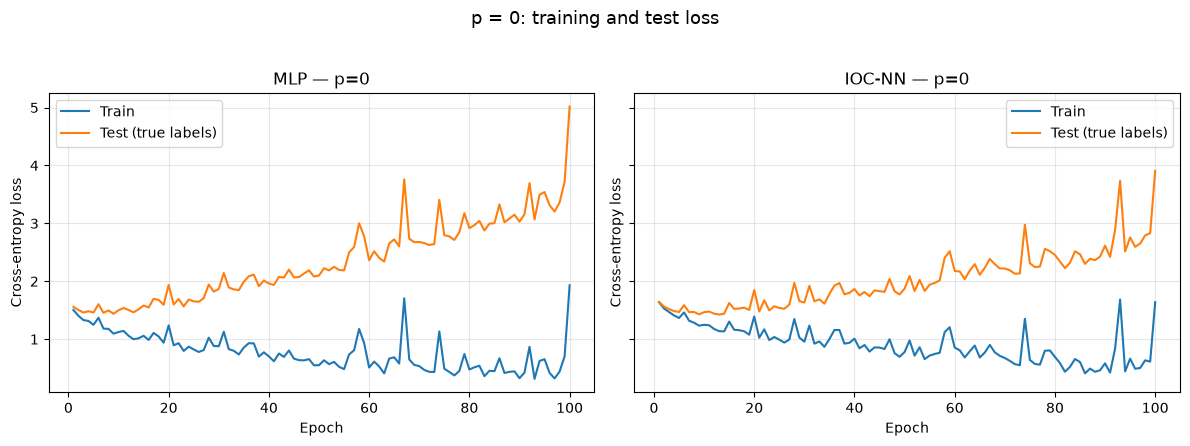

In [47]:
plot_curve(
    p=0.0,
    metric="loss",
    ylabel="Cross-entropy loss",
    title="p = 0: training and test loss",
)

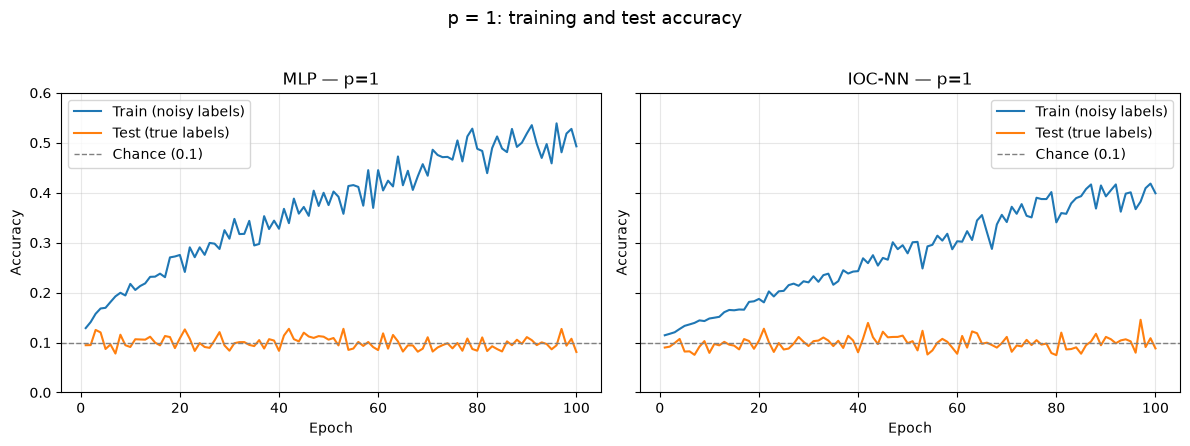

In [48]:
plot_curve(
    p=1.0,
    metric="acc",
    ylabel="Accuracy",
    title="p = 1: training and test accuracy",
    chance=0.1,
    ylim=(0.0, 0.6),
)

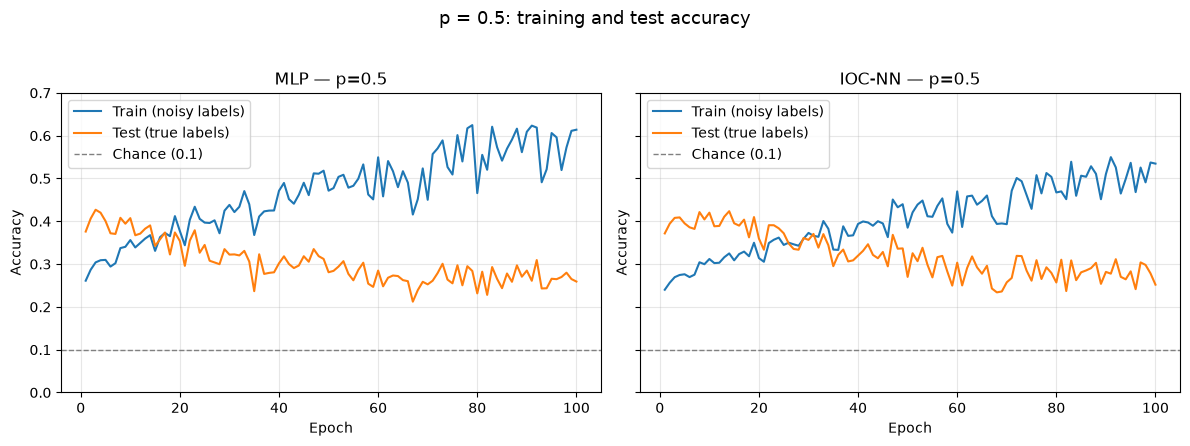

In [49]:
plot_curve(
    p=0.5,
    metric="acc",
    ylabel="Accuracy",
    title="p = 0.5: training and test accuracy",
    chance=0.1,
    ylim=(0.0, 0.7),
)